# 第16章：结果解释的证据边界

**学生实验｜全书深化稿**

## 背景与数据
固定人工响应模型的验证预测，用于分组残差、置换和条件bootstrap。

## 本次要回答的问题
检查按输入区间的误差，区分指标区间、单对象预测区间与训练不确定性。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 16: residual groups, correlated features and permutation importance."""
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance
from common import *

def run():
    tr,va,_=regression_demo();cols=['x','u']
    m=RandomForestRegressor(n_estimators=150,min_samples_leaf=3,random_state=42,n_jobs=1).fit(tr[cols],tr.target)
    pred=m.predict(va[cols]);errors=pred-va.target.to_numpy();rows=[]
    for lower,upper in [(-2.5,-1),(-1,1),(1,2.5)]:
        mask=(va.x>=lower)&(va.x<upper)
        rows.append({'group':f'[{lower},{upper})','count':int(mask.sum()),'mean_error':float(errors[mask].mean()),'RMSE':float(np.sqrt(np.mean(errors[mask]**2)))})
    df=table('ch16_group_errors',rows);show_result(df)
    table('ch16_residual_records',{'row_id':va.row_id.to_numpy(),'x':va.x.to_numpy(),'target':va.target.to_numpy(),'prediction':pred,'prediction_minus_target':errors})
    plt.figure(figsize=(6.4,4));plt.scatter(va.x,errors,s=20);plt.axhline(0,linestyle='--');plt.xlabel('人工输入 x');plt.ylabel('预测减目标（人工单位）');figure('v3_ch16_residuals')
    r=permutation_importance(m,va[cols],va.target,n_repeats=15,random_state=17,scoring='neg_root_mean_squared_error')
    table('ch16_importance',{'feature':cols,'mean_RMSE_increase':r.importances_mean,'repeat_std':r.importances_std})
    # Bootstrap uncertainty for the *fixed* predictions, not training-set uncertainty.
    rng=np.random.default_rng(160);boot=[]
    for b in range(1000):
        ids=rng.integers(0,len(errors),len(errors));boot.append(np.sqrt(np.mean(errors[ids]**2)))
    dump('ch16_fixed_model_bootstrap',{'RMSE':np.sqrt(np.mean(errors**2)),'percentile_2.5':np.quantile(boot,.025),'percentile_97.5':np.quantile(boot,.975),'scope':'fixed predictions, IID row resampling of synthetic validation sample'})

In [3]:
result = run()
if result is not None:
    print(result)

    group  count  mean_error     RMSE
[-2.5,-1)     18    0.091246 0.338266
   [-1,1)     27   -0.055108 0.327683
  [1,2.5)     15   -0.046952 0.380620


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch16_residuals.png


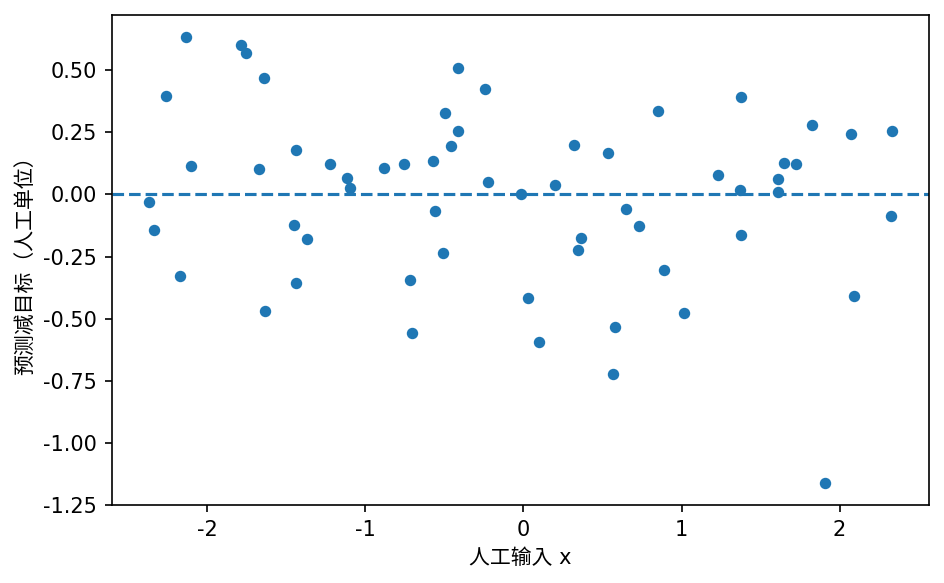

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch16_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

检查按输入区间的误差，区分指标区间、单对象预测区间与训练不确定性。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。